# Email Spam Detection Using Machine Learning

### Oasis Infobyte Internship – Data Science

**Task:** Task 4 – Email Spam Detection

**Student Name:** Sarvesh Sachin Ghadi

**Technologies Used:**
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- TF-IDF Vectorization
- Naive Bayes
- Logistic Regression

### Project Objective
The objective of this project is to develop a Machine Learning model that can classify text messages as Spam or Ham (Not Spam).

In [1]:
# Import Required Libraries

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
# Load SMS Spam Dataset

df = pd.read_csv(
    "dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset Loaded Successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Loaded Successfully!

Dataset Shape: (5572, 2)

First 5 Records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [3]:
# Dataset Analysis

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nClass Distribution Percentage:")
print(df["label"].value_counts(normalize=True) * 100)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records:
403

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class Distribution Percentage:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [4]:
# Remove Duplicate Records

df = df.drop_duplicates().copy()

# Convert Labels into Numeric Values
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

# Text Cleaning Function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply Text Cleaning
df["clean_message"] = df["message"].apply(clean_text)

print("Data Cleaning Completed!")

print("\nCleaned Dataset Shape:", df.shape)

print("\nCleaned Messages:")
display(df[["label", "message", "clean_message"]].head())

Data Cleaning Completed!

Cleaned Dataset Shape: (5169, 3)

Cleaned Messages:


,label,message,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,0,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


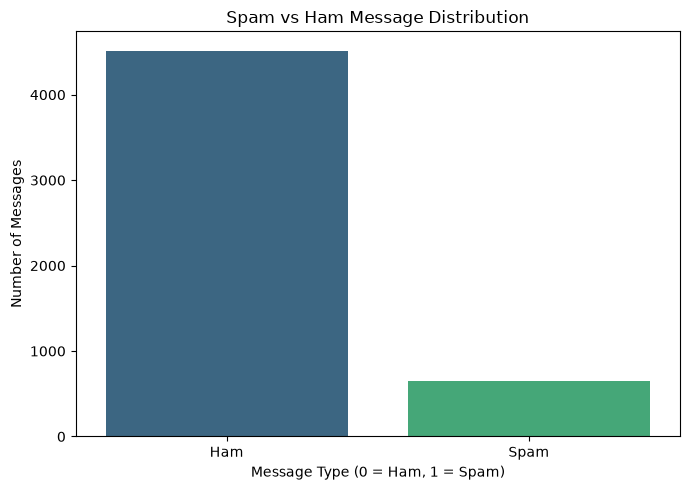

In [5]:
# Visualize Spam and Ham Messages

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette="viridis",
    legend=False
)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Type (0 = Ham, 1 = Spam)")
plt.ylabel("Number of Messages")
plt.xticks([0, 1], ["Ham", "Spam"])

plt.tight_layout()
plt.show()

In [6]:
# Separate Features and Target

X = df["clean_message"]
y = df["label"]

# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Apply TF-IDF Vectorization

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization Completed!")

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

TF-IDF Vectorization Completed!
Training Shape: (4135, 5000)
Testing Shape: (1034, 5000)


In [7]:
# Initialize Machine Learning Models

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

# Train Models
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "Model Trained Successfully!")

print("\nAll Models Training Completed!")

Naive Bayes Model Trained Successfully!
Logistic Regression Model Trained Successfully!

All Models Training Completed!


In [8]:
# Evaluate Machine Learning Models

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"]
    ))

# Display Model Comparison

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df)


Model: Naive Bayes
Accuracy: 0.97
Precision: 1.0
Recall: 0.7634
F1 Score: 0.8658

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       1.00      0.76      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034


Model: Logistic Regression
Accuracy: 0.9507
Precision: 0.9762
Recall: 0.626
F1 Score: 0.7628

Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       903
        Spam       0.98      0.63      0.76       131

    accuracy                           0.95      1034
   macro avg       0.96      0.81      0.87      1034
weighted avg       0.95      0.95      0.95      1034


Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.970019,1.00000,0.763359,0.865801
1,Logistic Regression,0.950677,0.97619,0.625954,0.762791


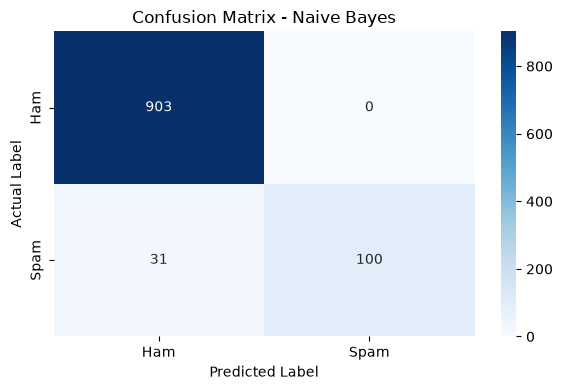

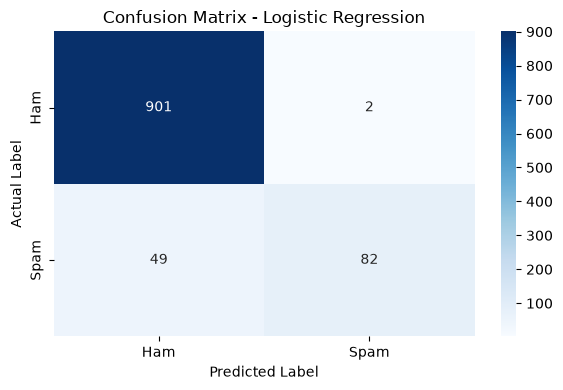

In [9]:
# Confusion Matrix Visualization

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

In [10]:
# Select Best Model
best_model = models["Naive Bayes"]

# Function to Predict New Messages
def predict_message(message):

    cleaned = clean_text(message)

    transformed = tfidf.transform([cleaned])

    prediction = best_model.predict(transformed)[0]

    probability = best_model.predict_proba(transformed)[0]

    result = "SPAM" if prediction == 1 else "HAM (NOT SPAM)"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Spam Probability:", round(probability[1] * 100, 2), "%")


# Test Messages
predict_message("Congratulations! You have won a free prize. Call now!")

predict_message("Hey, are we meeting tomorrow?")


Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam Probability: 96.15 %

Message: Hey, are we meeting tomorrow?
Prediction: HAM (NOT SPAM)
Spam Probability: 0.65 %


## Conclusion

In this project, we developed an SMS Spam Detection system using Machine Learning techniques.

The dataset was cleaned and preprocessed by removing duplicate records and converting text messages into lowercase cleaned text.

TF-IDF Vectorization was used to convert text messages into numerical features.

Two Machine Learning algorithms were implemented:
1. Multinomial Naive Bayes
2. Logistic Regression

### Model Performance

- Naive Bayes Accuracy: 97%
- Logistic Regression Accuracy: 95.07%

Naive Bayes achieved the best overall performance among the two models.

The system successfully classified sample messages as Spam or Ham (Not Spam).

### Future Scope

- Improve spam detection accuracy.
- Use larger email and SMS datasets.
- Develop a web-based spam detection application.
- Integrate real-time message classification.

### Final Result

The project demonstrates how Natural Language Processing and Machine Learning can be used to identify unwanted spam messages.